# Unsupervised clustering

Clustering the survival data to look for patient subgroups. Plots are colored by
event status (Regional LN recurrence).

In [2]:
# Cell 1: Import libraries
import sys
import os
sys.path.append(os.path.abspath('../../'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Clustering algorithms
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering, SpectralClustering
from sklearn.mixture import GaussianMixture

# Dimensionality reduction
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# Preprocessing
from sklearn.preprocessing import StandardScaler

# Evaluation metrics
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

# Visualization
from scipy.cluster.hierarchy import dendrogram, linkage

import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid')
print("Libraries imported successfully")

Libraries imported successfully


In [3]:
# Cell 2: Load data
dataset = pd.read_csv("../data/data.csv")

# Load feature variable lists
diagnosis_variables = []
with open("../data/diagnosis.txt", "r") as file:
    for line in file:
        diagnosis_variables.append(line.strip())

treatment_variables = []
with open("../data/treatment.txt", "r") as file:
    for line in file:
        treatment_variables.append(line.strip())

survival_dataset = dataset.drop('Unnamed: 0', axis=1)
feature_columns = treatment_variables + diagnosis_variables

# Extract features and target
X = survival_dataset[feature_columns].copy()
# Original event/time columns (coerce to numeric to be safe)
event_status_raw = pd.to_numeric(survival_dataset['Regional LN recurrence'], errors='coerce').fillna(0).astype(int).values
survival_time = pd.to_numeric(survival_dataset['Survival days'], errors='coerce').fillna(0).astype(float).values
# Treat events that occur at or before 1825 days as non-events.
# Only events with survival_time > 1826 are considered events for this analysis.
event_status = np.where((event_status_raw == 1) & (survival_time > 1826), 1, 0)
n_original_events = int(event_status_raw.sum())
n_late_events = int(event_status.sum())
print(f"Dataset shape: {X.shape}")
print(f"Number of features: {len(feature_columns)}")
print(f"Original events: {n_original_events}; Late events (>1826 days): {n_late_events}")
print(f"Adjusted event rate (late events): {event_status.mean():.2%} ({n_late_events} events)")
print(f"\nFeature columns:")
print(feature_columns)

Dataset shape: (3228, 35)
Number of features: 35
Original events: 33; Late events (>1826 days): 6
Adjusted event rate (late events): 0.19% (6 events)

Feature columns:
['Adjuvant therapy using biological drugs', 'Radiotherapy (RT) performed', 'Radiotherapy on chest wall', 'Radiotherapy on supraclavicular area', 'Radiotherapy on internal mammary chain', 'State (if hormone therapy prescribed)', 'Treatment in association with chemotherapy', 'Chemotherapy performed', 'Adjuvant chemotherapy', 'Conventional RT fraction', 'Total administered dose', 'Boost dose administered', 'Neoadjuvant (Only) therapy with biological drugs', 'Age', 'Ki67 positive cells (%) at CB', 'Side location of the lesion', 'Grade at CB_1.0', 'Grade at CB_2.0', 'Grade at CB_3.0', 'Isotype at CB_1.0', 'Isotype at CB_2.0', 'Isotype at CB_3.0', 'Isotype at CB_4.0', 'Her2 overexpression (with immunohystochemistry) at CB_1.0', 'Her2 overexpression (with immunohystochemistry) at CB_2.0', 'Her2 overexpression (with immunohystoc

In [4]:
# Cell 3: Preprocess data - Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f"Scaled data shape: {X_scaled.shape}")
print(f"Mean of scaled features: {X_scaled.mean():.4f}")
print(f"Std of scaled features: {X_scaled.std():.4f}")

Scaled data shape: (3228, 35)
Mean of scaled features: 0.0000
Std of scaled features: 1.0000


In [ ]:
# Cell 4: PCA - Dimensionality Reduction
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print(f"Explained variance ratio: {pca.explained_variance_ratio_}")
print(f"Total variance explained: {sum(pca.explained_variance_ratio_):.2%}")

# Visualize PCA by late-event status, showing all samples
fig, ax = plt.subplots(figsize=(10, 8))

colors = ['#95a5a6', '#e74c3c']  # Gray for other samples, Red for late events
labels = ['Other', 'Late Event']

for i, (color, label) in enumerate(zip(colors, labels)):
    mask = event_status == i
    ax.scatter(X_pca[mask, 0], X_pca[mask, 1], c=color, label=label,
               alpha=0.6, s=50, edgecolors='white', linewidth=0.5)

ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)', fontsize=12)
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)', fontsize=12)
ax.set_title('PCA - 2D Projection with Late Events Highlighted', fontsize=14)
ax.legend(title='Status', fontsize=10)
plt.tight_layout()
plt.show()

## Early vs. late recurrence: does the biology shift at 5 years?

The plot above colors all patients by late-event status, but a formal test of whether
the 6 late events form a distinguishable multivariate subgroup (fitting a plane through
their PCA coordinates, correlating event status with each PC) doesn't survive a
permutation test against the population still at risk beyond 5 years (compactness
p ≈ 0.30, coplanarity p ≈ 0.51). With only 6 events, PCA/plane-fitting has no real power
to detect structure against 3222 non-events, and the fitted plane visually cuts through
the whole point cloud, not just the late events.

A more targeted question, grounded in known breast cancer biology: do recurrences
**before** vs. **after** the 5-year (1826-day) mark differ from *each other*?
Hormone-receptor-positive tumors are known to carry a long, roughly constant recurrence
hazard extending well past 5 years, while receptor-negative/high-proliferation disease
recurs early and rarely relapses late. If that pattern holds here, it supports the
5-year cut as a real biological boundary rather than just a modeling convenience, and
helps explain why a model whose signal is dominated by early-recurrence cases may not
capture the late-recurrence tail.

Tested here: a pre-specified panel of clinical/pathology markers (fixed before testing,
not selected post hoc), early (n=27) vs. late (n=6) recurrences.

In [ ]:
# Cell 4b: Early vs. Late Recurrence -- Biology Comparison Table
from scipy.stats import mannwhitneyu, fisher_exact

early_mask = (event_status_raw == 1) & (survival_time <= 1826)
late_mask = (event_status_raw == 1) & (survival_time > 1826)
early_df = survival_dataset[early_mask]
late_df = survival_dataset[late_mask]
n_early = int(early_mask.sum())
n_late = int(late_mask.sum())
print(f"Early recurrences (<=1826 days): n={n_early}")
print(f"Late recurrences (>1826 days):  n={n_late}")

# Pre-specified panel of clinical/pathology markers, fixed before testing to avoid
# fishing across all 35 features.
continuous_panel = ['Age', 'Ki67 positive cells (%) at CB']
categorical_panel = [
    'Oestrogen receptor status at CB',
    'Progesterone receptor status at CB',
    'Type of invasion at CB',
    'Grade at CB_2.0', 'Grade at CB_3.0',
    'Isotype at CB_1.0', 'Isotype at CB_4.0',
    'Her2 overexpression (with immunohystochemistry) at CB_3.0',
    'N (Regional nodes affected)_0.0', 'N (Regional nodes affected)_1.0',
]
n_tests = len(continuous_panel) + len(categorical_panel)
early_col, late_col = f'Early (n={n_early})', f'Late (n={n_late})'

rows = []
for var in continuous_panel:
    e = pd.to_numeric(early_df[var], errors='coerce').dropna()
    l = pd.to_numeric(late_df[var], errors='coerce').dropna()
    _, p_value = mannwhitneyu(e, l, alternative='two-sided')
    rows.append({
        'Variable': var,
        early_col: f'{e.median():.1f} [{e.quantile(.25):.1f}-{e.quantile(.75):.1f}]',
        late_col: f'{l.median():.1f} [{l.quantile(.25):.1f}-{l.quantile(.75):.1f}]',
        'Test': 'Mann-Whitney U',
        'p': p_value,
        'p (Bonferroni)': min(p_value * n_tests, 1.0),
    })

for var in categorical_panel:
    e = pd.to_numeric(early_df[var], errors='coerce')
    l = pd.to_numeric(late_df[var], errors='coerce')
    e1, e0 = int((e == 1).sum()), int((e == 0).sum())
    l1, l0 = int((l == 1).sum()), int((l == 0).sum())
    _, p_value = fisher_exact([[e1, e0], [l1, l0]])
    rows.append({
        'Variable': var,
        early_col: f'{e1}/{e1 + e0} ({e1 / (e1 + e0):.0%})',
        late_col: f'{l1}/{l1 + l0} ({l1 / (l1 + l0):.0%})',
        'Test': "Fisher's exact",
        'p': p_value,
        'p (Bonferroni)': min(p_value * n_tests, 1.0),
    })

recurrence_biology_table = pd.DataFrame(rows)
recurrence_biology_table.to_csv('early_vs_late_recurrence_biology.csv', index=False)
recurrence_biology_table

In [ ]:
# Cell 4c: Figure - Early vs. Late Recurrence Biology
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

rate_vars = ['Oestrogen receptor status at CB', 'Progesterone receptor status at CB']
rate_labels = ['ER+', 'PR+']
early_rates = [pd.to_numeric(early_df[v], errors='coerce').mean() for v in rate_vars]
late_rates = [pd.to_numeric(late_df[v], errors='coerce').mean() for v in rate_vars]

x = np.arange(len(rate_labels))
width = 0.35
ax1 = axes[0]
ax1.bar(x - width / 2, early_rates, width, label=f'Early recurrence (n={n_early})', color='#3498db')
ax1.bar(x + width / 2, late_rates, width, label=f'Late recurrence (n={n_late})', color='#e74c3c')
ax1.set_xticks(x)
ax1.set_xticklabels(rate_labels)
ax1.set_ylabel('Positivity rate')
ax1.set_ylim(0, 1.15)
ax1.set_title('Hormone receptor status')
ax1.legend()
for i, (er, lr) in enumerate(zip(early_rates, late_rates)):
    ax1.text(i - width / 2, er + 0.03, f'{er:.0%}', ha='center', fontsize=9)
    ax1.text(i + width / 2, lr + 0.03, f'{lr:.0%}', ha='center', fontsize=9)

ax2 = axes[1]
ki67_early = pd.to_numeric(early_df['Ki67 positive cells (%) at CB'], errors='coerce').dropna()
ki67_late = pd.to_numeric(late_df['Ki67 positive cells (%) at CB'], errors='coerce').dropna()
bp = ax2.boxplot([ki67_early, ki67_late],
                 labels=[f'Early\n(n={len(ki67_early)})', f'Late\n(n={len(ki67_late)})'],
                 patch_artist=True, widths=0.5)
for patch, color in zip(bp['boxes'], ['#3498db', '#e74c3c']):
    patch.set_facecolor(color)
    patch.set_alpha(0.6)
ax2.set_ylabel('Ki67 positive cells (%)')
ax2.set_title('Proliferation index (Ki67)')

plt.suptitle('Early vs. late recurrence: biology shifts around the 5-year mark', fontsize=13)
plt.tight_layout()
plt.savefig('early_vs_late_recurrence_biology.pdf', bbox_inches='tight')
plt.show()
print("Figure saved to 'early_vs_late_recurrence_biology.pdf'")

Computing t-SNE (this may take a moment)...


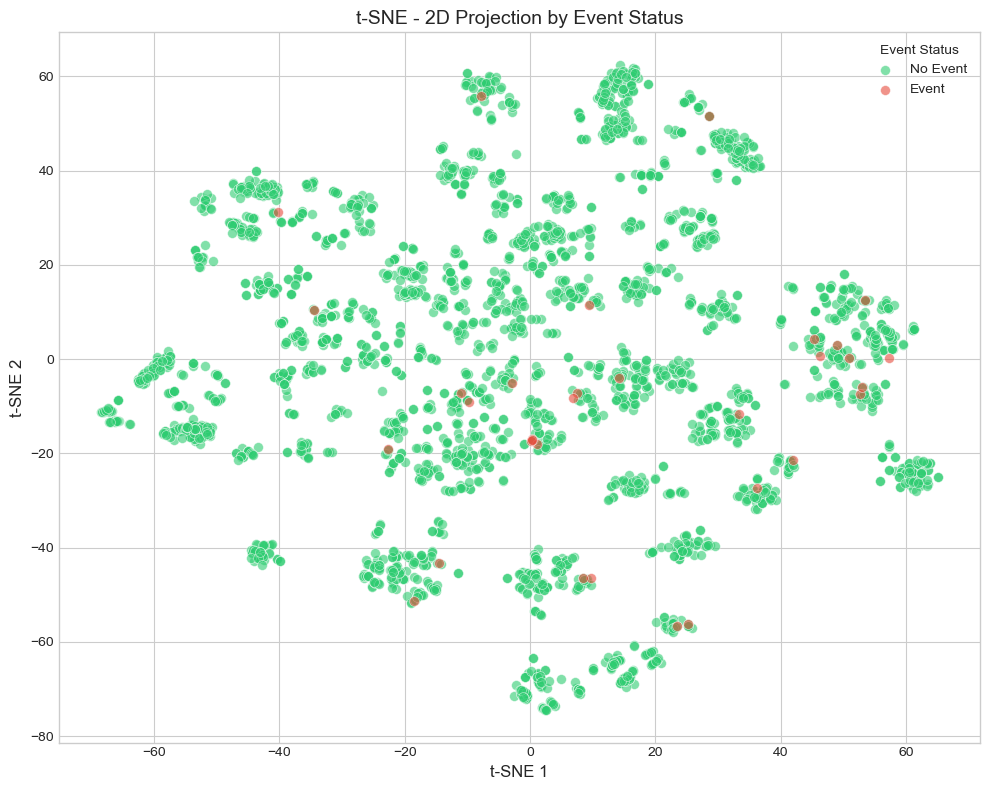

In [5]:
# Cell 5: t-SNE - Dimensionality Reduction
print("Computing t-SNE (this may take a moment)...")
tsne = TSNE(n_components=2, perplexity=30, random_state=42)
X_tsne = tsne.fit_transform(X_scaled)

# Visualize t-SNE by event status
fig, ax = plt.subplots(figsize=(10, 8))

for i, (color, label) in enumerate(zip(colors, labels)):
    mask = event_status == i
    ax.scatter(X_tsne[mask, 0], X_tsne[mask, 1], c=color, label=label, 
               alpha=0.6, s=50, edgecolors='white', linewidth=0.5)

ax.set_xlabel('t-SNE 1', fontsize=12)
ax.set_ylabel('t-SNE 2', fontsize=12)
ax.set_title('t-SNE - 2D Projection by Event Status', fontsize=14)
ax.legend(title='Event Status', fontsize=10)
plt.tight_layout()
plt.show()

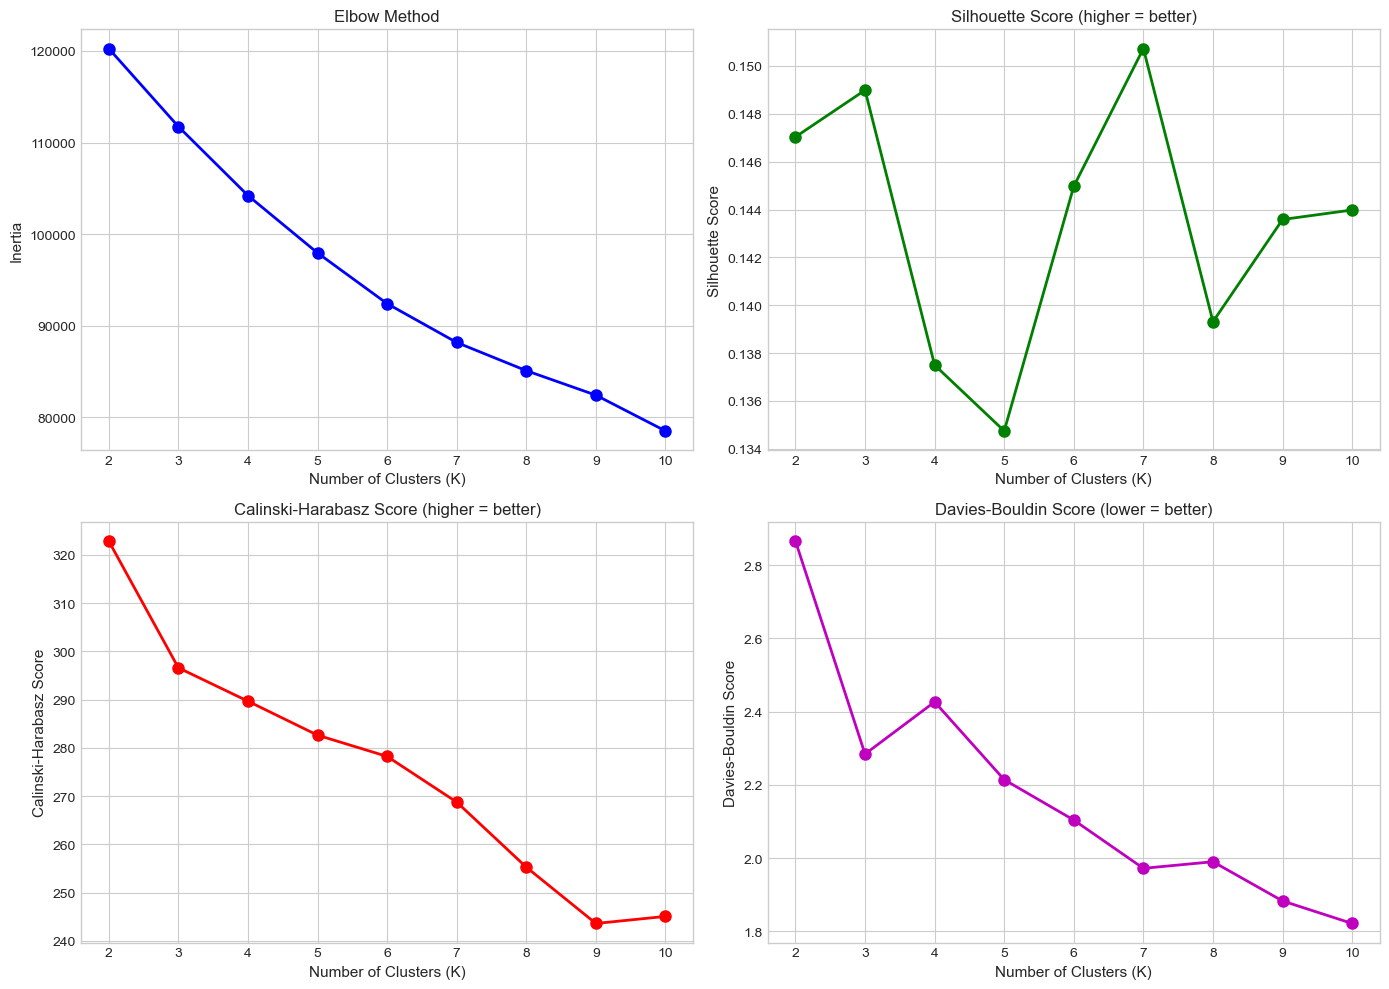


Best K based on Silhouette Score: 7


In [6]:
# Cell 6: Elbow Method and Silhouette Analysis to find optimal K
k_range = range(2, 11)
inertias = []
silhouette_scores = []
calinski_scores = []
davies_bouldin_scores = []

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    inertias.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, labels))
    calinski_scores.append(calinski_harabasz_score(X_scaled, labels))
    davies_bouldin_scores.append(davies_bouldin_score(X_scaled, labels))

# Plot evaluation metrics
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Elbow plot
axes[0, 0].plot(k_range, inertias, 'bo-', linewidth=2, markersize=8)
axes[0, 0].set_xlabel('Number of Clusters (K)', fontsize=11)
axes[0, 0].set_ylabel('Inertia', fontsize=11)
axes[0, 0].set_title('Elbow Method', fontsize=12)

# Silhouette Score
axes[0, 1].plot(k_range, silhouette_scores, 'go-', linewidth=2, markersize=8)
axes[0, 1].set_xlabel('Number of Clusters (K)', fontsize=11)
axes[0, 1].set_ylabel('Silhouette Score', fontsize=11)
axes[0, 1].set_title('Silhouette Score (higher = better)', fontsize=12)

# Calinski-Harabasz Score
axes[1, 0].plot(k_range, calinski_scores, 'ro-', linewidth=2, markersize=8)
axes[1, 0].set_xlabel('Number of Clusters (K)', fontsize=11)
axes[1, 0].set_ylabel('Calinski-Harabasz Score', fontsize=11)
axes[1, 0].set_title('Calinski-Harabasz Score (higher = better)', fontsize=12)

# Davies-Bouldin Score
axes[1, 1].plot(k_range, davies_bouldin_scores, 'mo-', linewidth=2, markersize=8)
axes[1, 1].set_xlabel('Number of Clusters (K)', fontsize=11)
axes[1, 1].set_ylabel('Davies-Bouldin Score', fontsize=11)
axes[1, 1].set_title('Davies-Bouldin Score (lower = better)', fontsize=12)

plt.tight_layout()
plt.show()

# Print best K based on silhouette
best_k_silhouette = k_range[np.argmax(silhouette_scores)]
print(f"\nBest K based on Silhouette Score: {best_k_silhouette}")


=== K-Means with K=2 ===
Silhouette Score: 0.1470
  Cluster 0: 975 samples, 22 events (2.3%)
  Cluster 1: 2252 samples, 11 events (0.5%)

=== K-Means with K=3 ===
Silhouette Score: 0.1490
  Cluster 0: 335 samples, 5 events (1.5%)
  Cluster 1: 687 samples, 14 events (2.0%)
  Cluster 2: 2205 samples, 14 events (0.6%)

=== K-Means with K=4 ===
Silhouette Score: 0.1375
  Cluster 0: 880 samples, 6 events (0.7%)
  Cluster 1: 1607 samples, 11 events (0.7%)
  Cluster 2: 414 samples, 11 events (2.7%)
  Cluster 3: 326 samples, 5 events (1.5%)

=== K-Means with K=5 ===
Silhouette Score: 0.1347
  Cluster 0: 1375 samples, 4 events (0.3%)
  Cluster 1: 431 samples, 13 events (3.0%)
  Cluster 2: 472 samples, 8 events (1.7%)
  Cluster 3: 166 samples, 2 events (1.2%)
  Cluster 4: 783 samples, 6 events (0.8%)


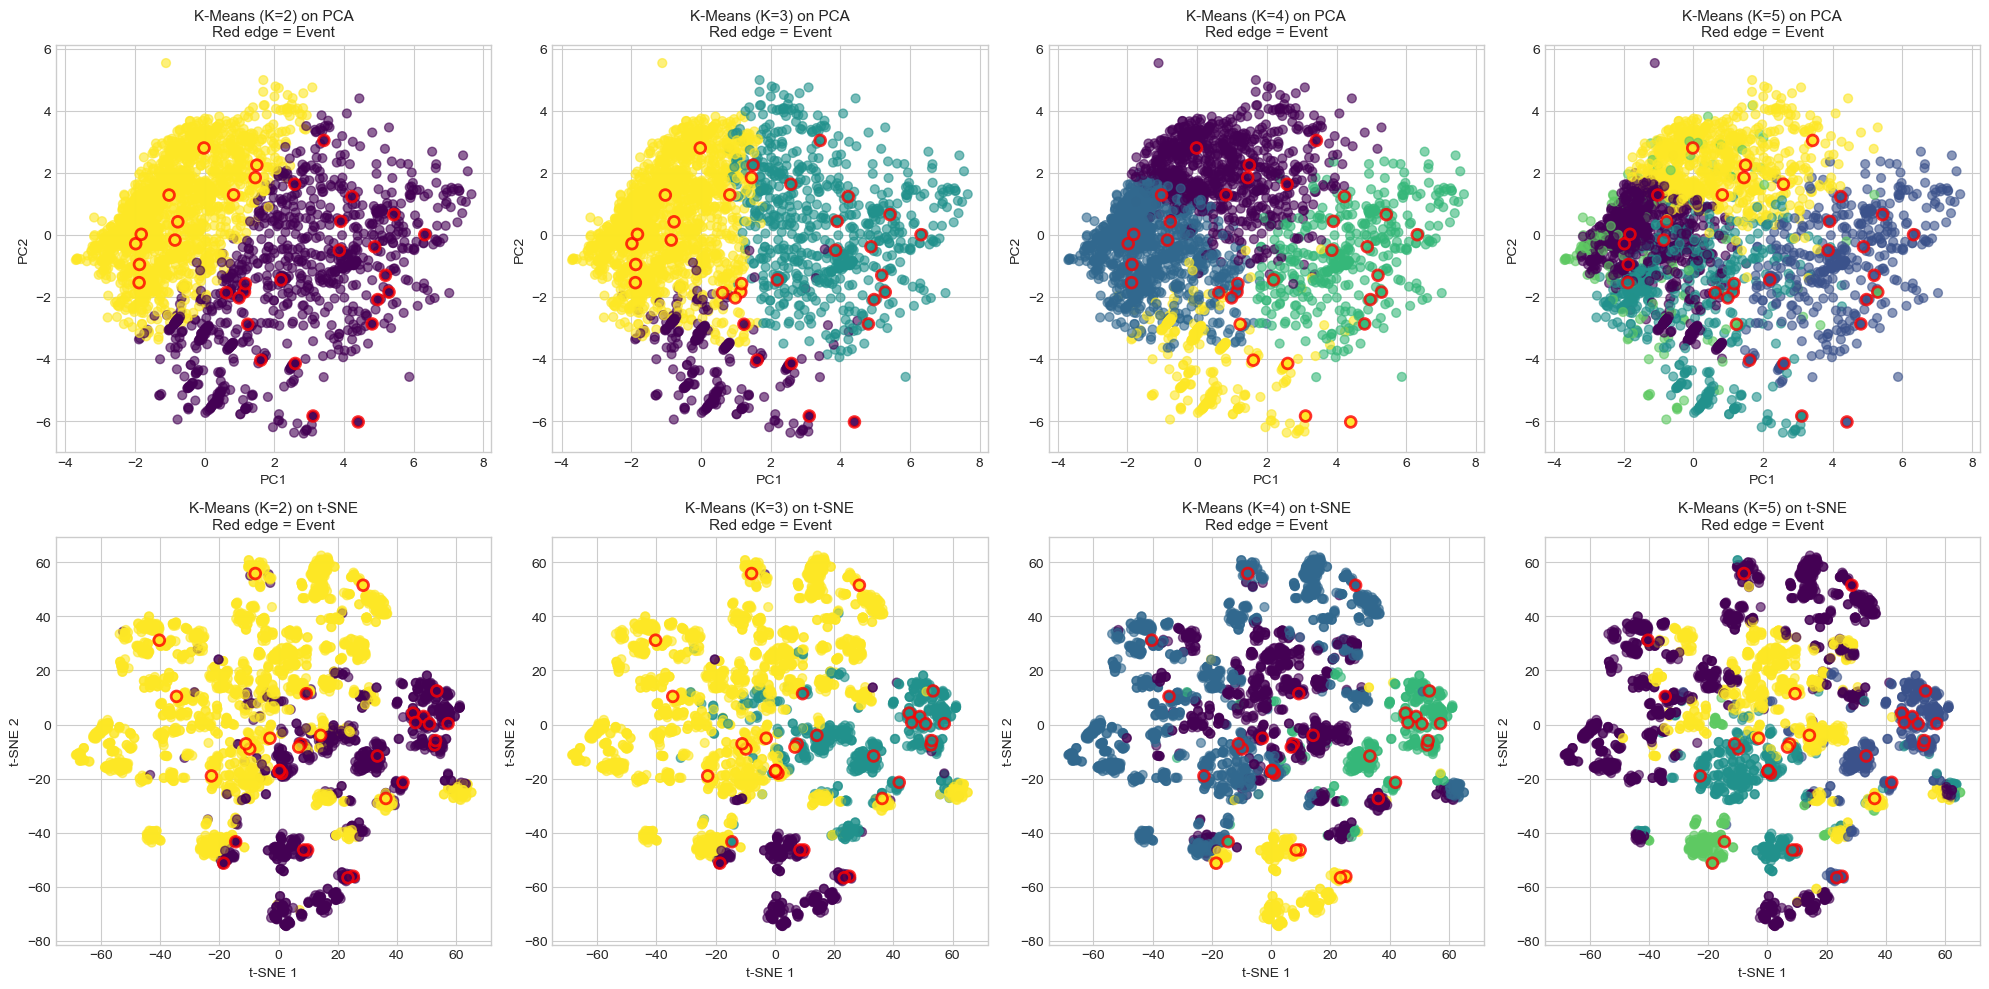

In [7]:
# Cell 7: K-Means Clustering - Multiple K values
n_clusters_list = [2, 3, 4, 5]

fig, axes = plt.subplots(2, 4, figsize=(20, 10))

for idx, n_clusters in enumerate(n_clusters_list):
    kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
    cluster_labels = kmeans.fit_predict(X_scaled)
    
    # Plot clusters on PCA (top row)
    ax1 = axes[0, idx]
    scatter = ax1.scatter(X_pca[:, 0], X_pca[:, 1], c=cluster_labels, 
                          cmap='viridis', alpha=0.6, s=40)
    # Mark event points with red edge
    event_mask = event_status == 1
    ax1.scatter(X_pca[event_mask, 0], X_pca[event_mask, 1], 
                c=cluster_labels[event_mask], cmap='viridis',
                edgecolors='red', linewidth=2, s=60, marker='o', alpha=0.8,
                label='Event')
    ax1.set_title(f'K-Means (K={n_clusters}) on PCA\nRed edge = Event', fontsize=11)
    ax1.set_xlabel('PC1')
    ax1.set_ylabel('PC2')
    
    # Plot clusters on t-SNE (bottom row)
    ax2 = axes[1, idx]
    scatter = ax2.scatter(X_tsne[:, 0], X_tsne[:, 1], c=cluster_labels, 
                          cmap='viridis', alpha=0.6, s=40)
    ax2.scatter(X_tsne[event_mask, 0], X_tsne[event_mask, 1], 
                c=cluster_labels[event_mask], cmap='viridis',
                edgecolors='red', linewidth=2, s=60, marker='o', alpha=0.8)
    ax2.set_title(f'K-Means (K={n_clusters}) on t-SNE\nRed edge = Event', fontsize=11)
    ax2.set_xlabel('t-SNE 1')
    ax2.set_ylabel('t-SNE 2')
    
    # Print cluster statistics
    print(f"\n=== K-Means with K={n_clusters} ===")
    print(f"Silhouette Score: {silhouette_score(X_scaled, cluster_labels):.4f}")
    for c in range(n_clusters):
        cluster_mask = cluster_labels == c
        n_in_cluster = cluster_mask.sum()
        events_in_cluster = event_status[cluster_mask].sum()
        event_rate = events_in_cluster / n_in_cluster if n_in_cluster > 0 else 0
        print(f"  Cluster {c}: {n_in_cluster} samples, {int(events_in_cluster)} events ({event_rate:.1%})")

plt.tight_layout()
plt.show()

Computing hierarchical clustering...


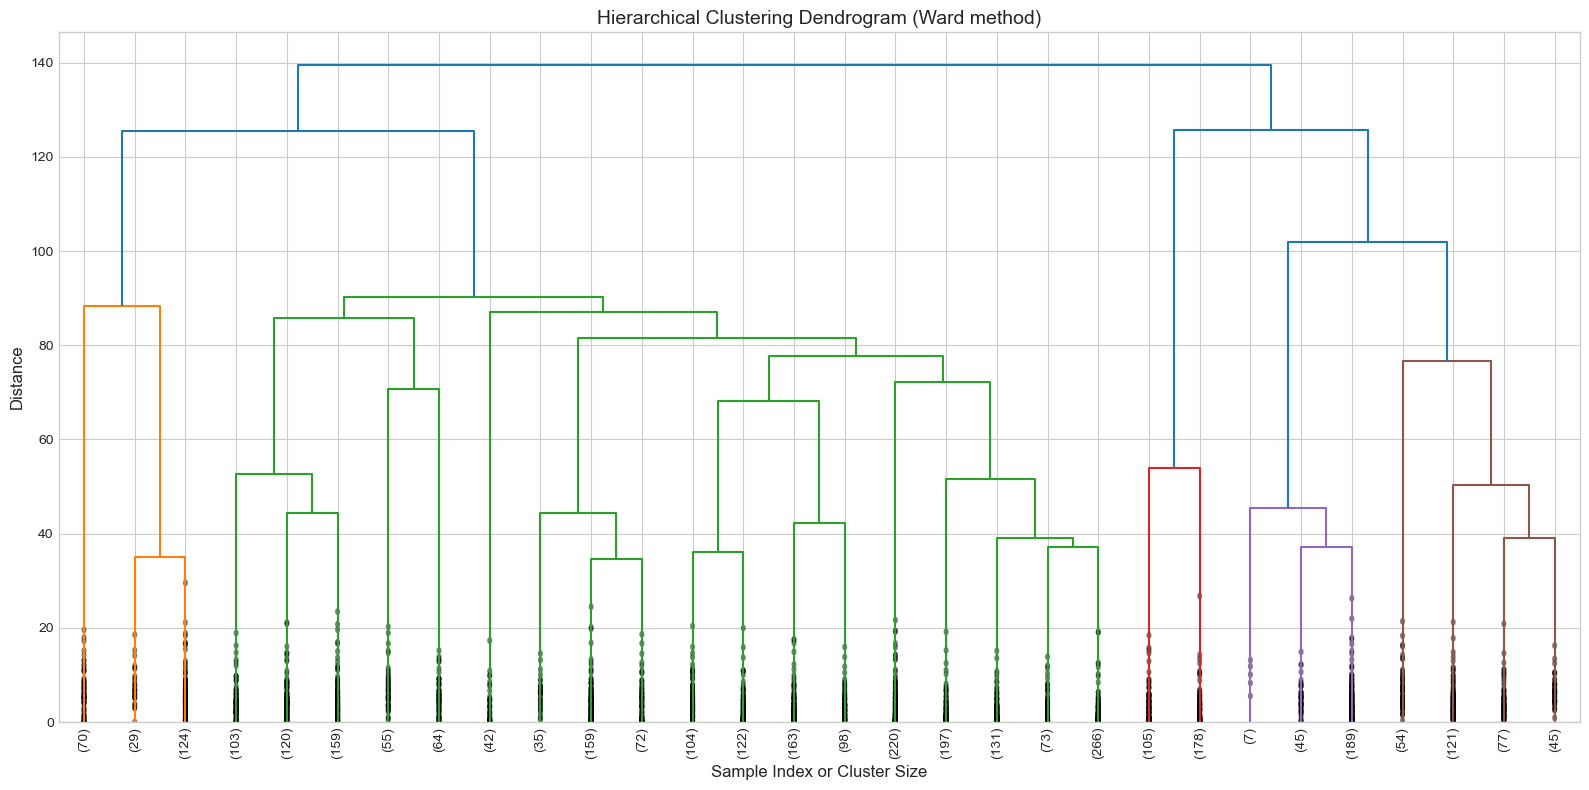

In [8]:
# Cell 8: Hierarchical Clustering with Dendrogram
# Compute linkage matrix
print("Computing hierarchical clustering...")
linkage_matrix = linkage(X_scaled, method='ward')

# Plot dendrogram
fig, ax = plt.subplots(figsize=(16, 8))
dendrogram(linkage_matrix, truncate_mode='lastp', p=30, 
           leaf_rotation=90., leaf_font_size=10., show_contracted=True, ax=ax)
ax.set_title('Hierarchical Clustering Dendrogram (Ward method)', fontsize=14)
ax.set_xlabel('Sample Index or Cluster Size', fontsize=12)
ax.set_ylabel('Distance', fontsize=12)
plt.tight_layout()
plt.show()

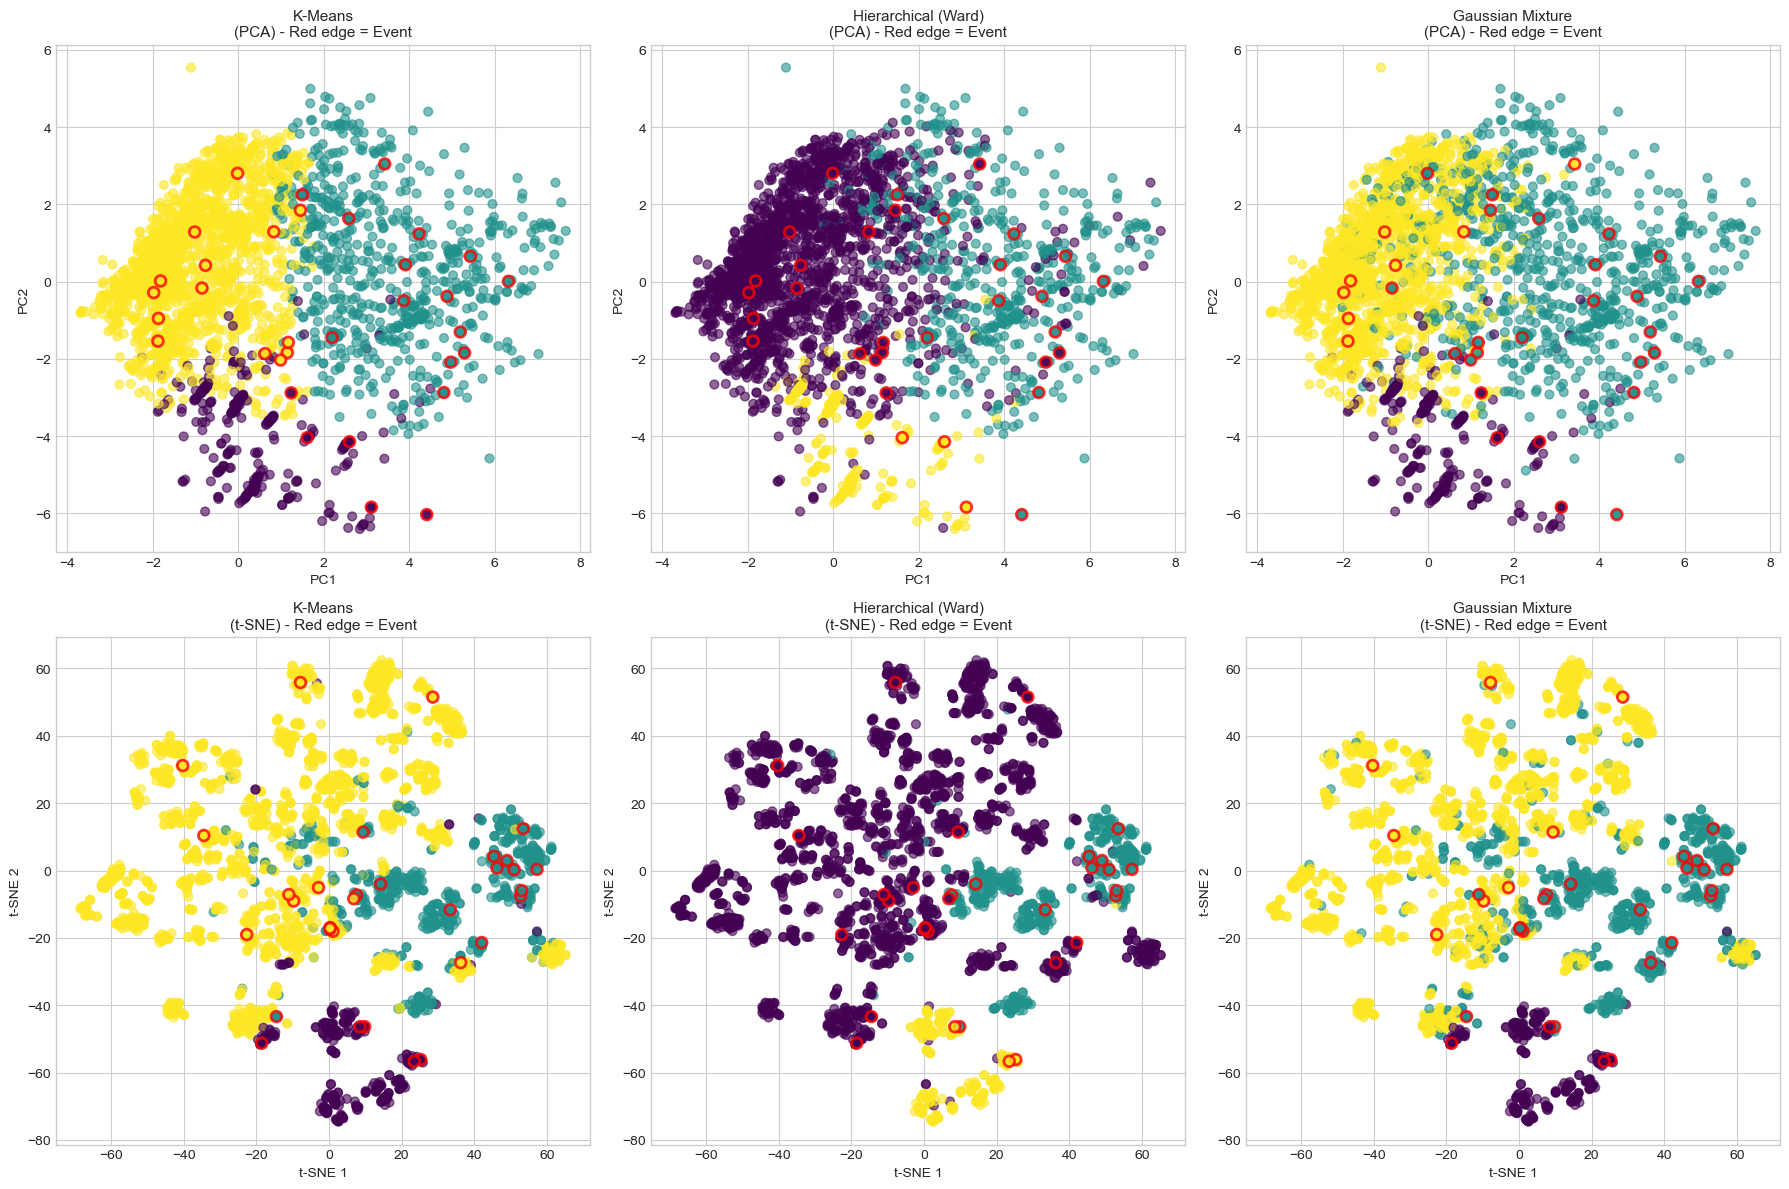

In [9]:
# Cell 9: Compare Multiple Clustering Algorithms
n_clusters = 3  # You can adjust this

# Initialize clustering algorithms
clustering_methods = {
    'K-Means': KMeans(n_clusters=n_clusters, random_state=42, n_init=10),
    'Hierarchical (Ward)': AgglomerativeClustering(n_clusters=n_clusters, linkage='ward'),
    'Gaussian Mixture': GaussianMixture(n_components=n_clusters, random_state=42),
}

# Store results
cluster_results = {}

fig, axes = plt.subplots(2, 3, figsize=(18, 12))

for idx, (name, model) in enumerate(clustering_methods.items()):
    # Fit and predict
    if hasattr(model, 'fit_predict'):
        labels = model.fit_predict(X_scaled)
    else:
        model.fit(X_scaled)
        labels = model.predict(X_scaled)
    
    cluster_results[name] = labels
    
    # Plot on PCA (top row)
    ax1 = axes[0, idx]
    scatter = ax1.scatter(X_pca[:, 0], X_pca[:, 1], c=labels, 
                          cmap='viridis', alpha=0.6, s=40)
    event_mask = event_status == 1
    ax1.scatter(X_pca[event_mask, 0], X_pca[event_mask, 1], 
                c=labels[event_mask], cmap='viridis',
                edgecolors='red', linewidth=2, s=60, alpha=0.8)
    ax1.set_title(f'{name}\n(PCA) - Red edge = Event', fontsize=11)
    ax1.set_xlabel('PC1')
    ax1.set_ylabel('PC2')
    
    # Plot on t-SNE (bottom row)
    ax2 = axes[1, idx]
    scatter = ax2.scatter(X_tsne[:, 0], X_tsne[:, 1], c=labels, 
                          cmap='viridis', alpha=0.6, s=40)
    ax2.scatter(X_tsne[event_mask, 0], X_tsne[event_mask, 1], 
                c=labels[event_mask], cmap='viridis',
                edgecolors='red', linewidth=2, s=60, alpha=0.8)
    ax2.set_title(f'{name}\n(t-SNE) - Red edge = Event', fontsize=11)
    ax2.set_xlabel('t-SNE 1')
    ax2.set_ylabel('t-SNE 2')

plt.tight_layout()
plt.show()

In [10]:
# Cell 10: Evaluate and Compare Clustering Methods
print("=" * 70)
print("CLUSTERING EVALUATION SUMMARY")
print("=" * 70)

results_summary = []

for name, labels in cluster_results.items():
    n_unique = len(np.unique(labels))
    if n_unique > 1:  # Silhouette requires at least 2 clusters
        sil = silhouette_score(X_scaled, labels)
        cal = calinski_harabasz_score(X_scaled, labels)
        db = davies_bouldin_score(X_scaled, labels)
        ari = adjusted_rand_score(event_status, labels)
        nmi = normalized_mutual_info_score(event_status, labels)
    else:
        sil, cal, db, ari, nmi = np.nan, np.nan, np.nan, np.nan, np.nan
    
    results_summary.append({
        'Method': name,
        'Silhouette': sil,
        'Calinski-Harabasz': cal,
        'Davies-Bouldin': db,
        'ARI (vs Event)': ari,
        'NMI (vs Event)': nmi
    })
    
    print(f"\n{name}:")
    print(f"  Silhouette Score: {sil:.4f}" if not np.isnan(sil) else "  Silhouette Score: N/A")
    print(f"  Calinski-Harabasz: {cal:.2f}" if not np.isnan(cal) else "  Calinski-Harabasz: N/A")
    print(f"  Davies-Bouldin: {db:.4f}" if not np.isnan(db) else "  Davies-Bouldin: N/A")
    print(f"  Adjusted Rand Index (vs Event): {ari:.4f}" if not np.isnan(ari) else "  ARI: N/A")
    print(f"  Normalized Mutual Info (vs Event): {nmi:.4f}" if not np.isnan(nmi) else "  NMI: N/A")
    
    # Event distribution per cluster
    print(f"  Cluster composition:")
    unique_labels = np.unique(labels)
    for c in unique_labels:
        cluster_mask = labels == c
        n_in_cluster = cluster_mask.sum()
        events_in_cluster = event_status[cluster_mask].sum()
        event_rate = events_in_cluster / n_in_cluster if n_in_cluster > 0 else 0
        print(f"    Cluster {c}: {n_in_cluster} samples, {int(events_in_cluster)} events ({event_rate:.1%})")

# Create summary dataframe
summary_df = pd.DataFrame(results_summary)
print("\n" + "=" * 70)
print("Summary Table:")
print(summary_df.to_string(index=False))

CLUSTERING EVALUATION SUMMARY

K-Means:
  Silhouette Score: 0.1490
  Calinski-Harabasz: 296.59
  Davies-Bouldin: 2.2840
  Adjusted Rand Index (vs Event): 0.0107
  Normalized Mutual Info (vs Event): 0.0035
  Cluster composition:
    Cluster 0: 335 samples, 5 events (1.5%)
    Cluster 1: 687 samples, 14 events (2.0%)
    Cluster 2: 2205 samples, 14 events (0.6%)

Hierarchical (Ward):
  Silhouette Score: 0.1187
  Calinski-Harabasz: 247.82
  Davies-Bouldin: 2.2690
  Adjusted Rand Index (vs Event): 0.0114
  Normalized Mutual Info (vs Event): 0.0031
  Cluster composition:
    Cluster 0: 2406 samples, 18 events (0.7%)
    Cluster 1: 538 samples, 12 events (2.2%)
    Cluster 2: 283 samples, 3 events (1.1%)

Gaussian Mixture:
  Silhouette Score: 0.1388
  Calinski-Harabasz: 267.17
  Davies-Bouldin: 2.5893
  Adjusted Rand Index (vs Event): 0.0125
  Normalized Mutual Info (vs Event): 0.0081
  Cluster composition:
    Cluster 0: 319 samples, 4 events (1.3%)
    Cluster 1: 836 samples, 21 events (2.

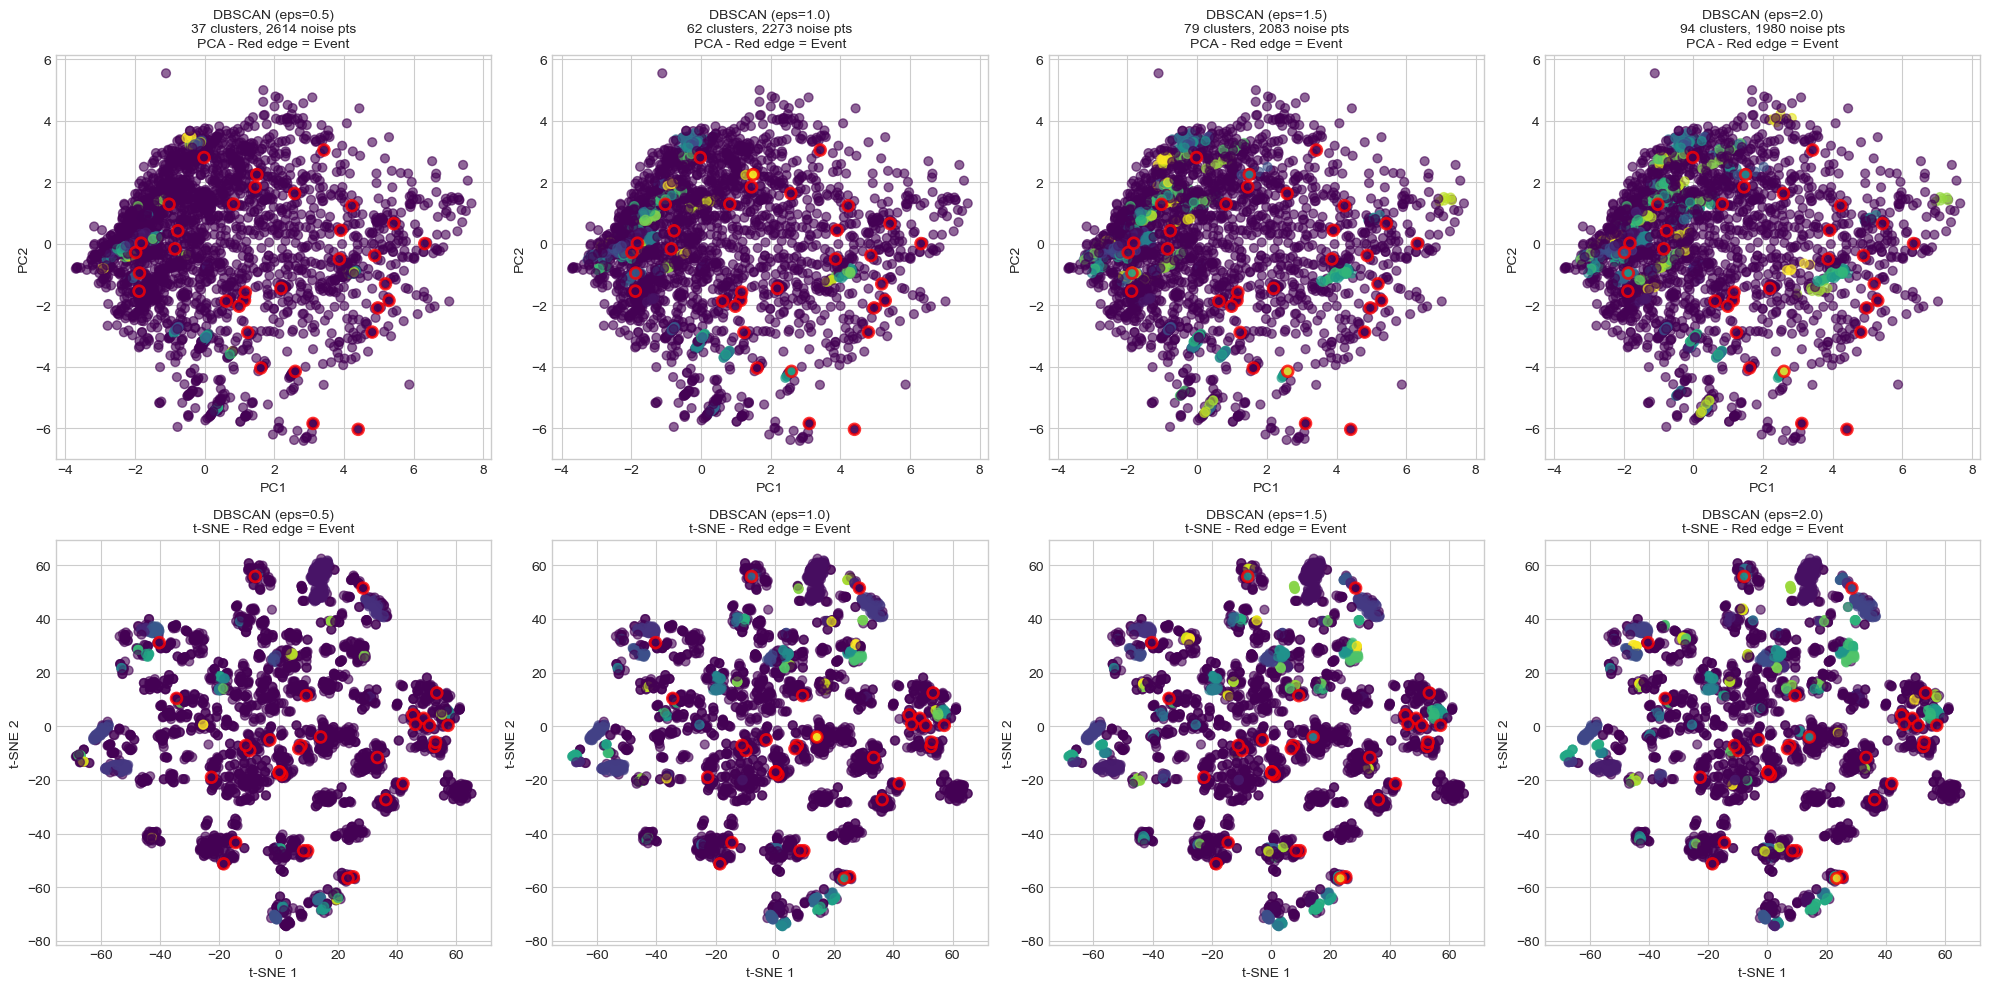

In [11]:
# Cell 11: DBSCAN Clustering (density-based)
# Try different eps values
eps_values = [0.5, 1.0, 1.5, 2.0]

fig, axes = plt.subplots(2, 4, figsize=(20, 10))

for idx, eps in enumerate(eps_values):
    dbscan = DBSCAN(eps=eps, min_samples=5)
    labels = dbscan.fit_predict(X_scaled)
    
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = list(labels).count(-1)
    
    # Plot on PCA (top row)
    ax1 = axes[0, idx]
    scatter = ax1.scatter(X_pca[:, 0], X_pca[:, 1], c=labels, 
                          cmap='viridis', alpha=0.6, s=40)
    event_mask = event_status == 1
    ax1.scatter(X_pca[event_mask, 0], X_pca[event_mask, 1], 
                c=labels[event_mask], cmap='viridis',
                edgecolors='red', linewidth=2, s=60, alpha=0.8)
    ax1.set_title(f'DBSCAN (eps={eps})\n{n_clusters} clusters, {n_noise} noise pts\nPCA - Red edge = Event', fontsize=10)
    ax1.set_xlabel('PC1')
    ax1.set_ylabel('PC2')
    
    # Plot on t-SNE (bottom row)
    ax2 = axes[1, idx]
    scatter = ax2.scatter(X_tsne[:, 0], X_tsne[:, 1], c=labels, 
                          cmap='viridis', alpha=0.6, s=40)
    ax2.scatter(X_tsne[event_mask, 0], X_tsne[event_mask, 1], 
                c=labels[event_mask], cmap='viridis',
                edgecolors='red', linewidth=2, s=60, alpha=0.8)
    ax2.set_title(f'DBSCAN (eps={eps})\nt-SNE - Red edge = Event', fontsize=10)
    ax2.set_xlabel('t-SNE 1')
    ax2.set_ylabel('t-SNE 2')

plt.tight_layout()
plt.show()

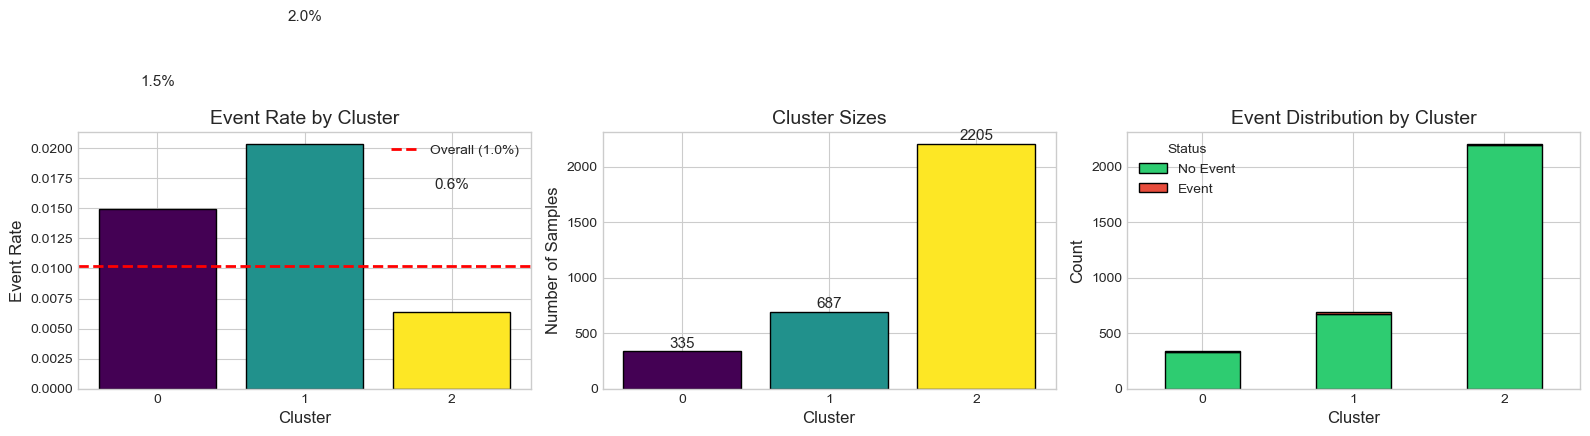


Cluster Summary:
--------------------------------------------------
Cluster 0: n=335, events=5, event_rate=1.5%, mean_survival_days=1278
Cluster 1: n=687, events=14, event_rate=2.0%, mean_survival_days=1406
Cluster 2: n=2205, events=14, event_rate=0.6%, mean_survival_days=1440


In [12]:
# Cell 12: Event Rate Analysis per Cluster (Best K-Means)
best_k = 3  # Adjust based on previous analysis
kmeans_best = KMeans(n_clusters=best_k, random_state=42, n_init=10)
cluster_labels_best = kmeans_best.fit_predict(X_scaled)

# Create dataframe for analysis
cluster_df = pd.DataFrame({
    'Cluster': cluster_labels_best,
    'Event': event_status,
    'Survival_Time': survival_time
})

# Event rate per cluster
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# 1. Event rate bar plot
event_rates = cluster_df.groupby('Cluster')['Event'].mean()
colors_bar = plt.cm.viridis(np.linspace(0, 1, best_k))
ax1 = axes[0]
bars = ax1.bar(range(best_k), event_rates.values, color=colors_bar, edgecolor='black')
ax1.axhline(y=event_status.mean(), color='red', linestyle='--', linewidth=2, label=f'Overall ({event_status.mean():.1%})')
ax1.set_xlabel('Cluster', fontsize=12)
ax1.set_ylabel('Event Rate', fontsize=12)
ax1.set_title('Event Rate by Cluster', fontsize=14)
ax1.set_xticks(range(best_k))
ax1.legend()
for bar, rate in zip(bars, event_rates.values):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, 
             f'{rate:.1%}', ha='center', va='bottom', fontsize=11)

# 2. Cluster size distribution
cluster_sizes = cluster_df.groupby('Cluster').size()
ax2 = axes[1]
ax2.bar(range(best_k), cluster_sizes.values, color=colors_bar, edgecolor='black')
ax2.set_xlabel('Cluster', fontsize=12)
ax2.set_ylabel('Number of Samples', fontsize=12)
ax2.set_title('Cluster Sizes', fontsize=14)
ax2.set_xticks(range(best_k))
for i, size in enumerate(cluster_sizes.values):
    ax2.text(i, size + 10, str(size), ha='center', va='bottom', fontsize=11)

# 3. Stacked bar - Event vs No Event per cluster
event_counts = cluster_df.groupby(['Cluster', 'Event']).size().unstack(fill_value=0)
ax3 = axes[2]
event_counts.plot(kind='bar', stacked=True, ax=ax3, color=['#2ecc71', '#e74c3c'], edgecolor='black')
ax3.set_xlabel('Cluster', fontsize=12)
ax3.set_ylabel('Count', fontsize=12)
ax3.set_title('Event Distribution by Cluster', fontsize=14)
ax3.legend(['No Event', 'Event'], title='Status')
ax3.set_xticklabels(ax3.get_xticklabels(), rotation=0)

plt.tight_layout()
plt.show()

# Print summary
print("\nCluster Summary:")
print("-" * 50)
for c in range(best_k):
    mask = cluster_labels_best == c
    n = mask.sum()
    events = event_status[mask].sum()
    rate = events / n if n > 0 else 0
    mean_surv = survival_time[mask].mean()
    print(f"Cluster {c}: n={n}, events={int(events)}, event_rate={rate:.1%}, mean_survival_days={mean_surv:.0f}")

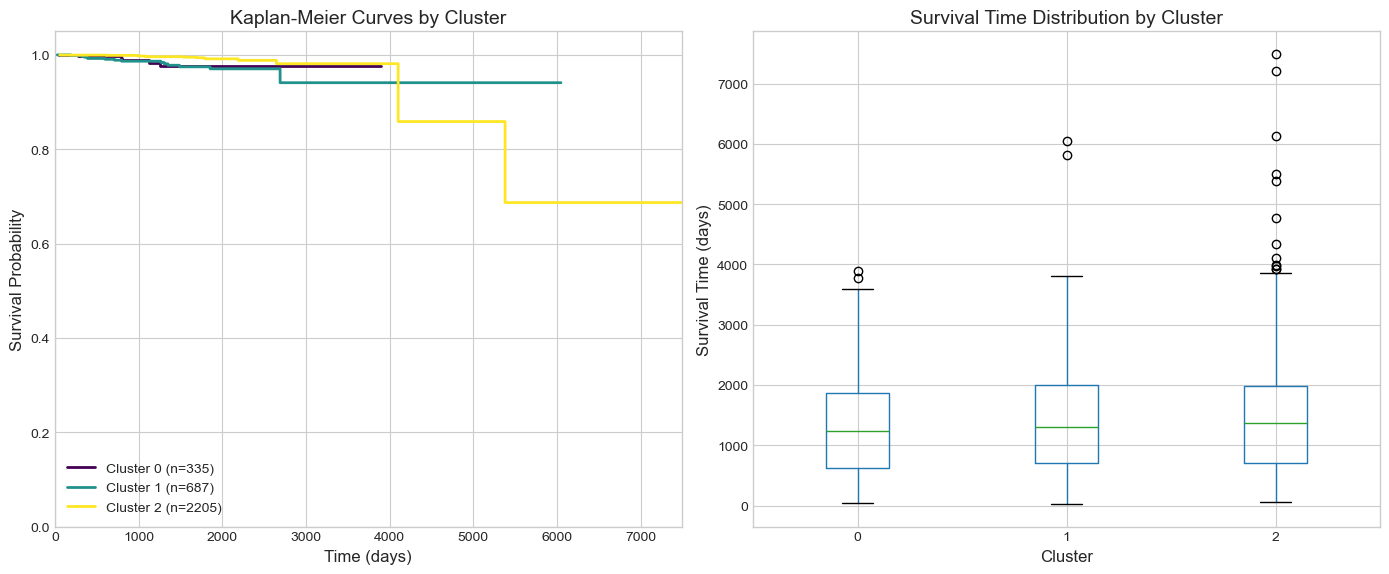

In [13]:
# Cell 13: Kaplan-Meier Survival Curves by Cluster
from sksurv.nonparametric import kaplan_meier_estimator

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Plot KM curves for each cluster
ax1 = axes[0]
colors_km = plt.cm.viridis(np.linspace(0, 1, best_k))

for cluster in range(best_k):
    mask = cluster_labels_best == cluster
    try:
        time, survival_prob = kaplan_meier_estimator(
            event_status[mask].astype(bool),
            survival_time[mask]
        )
        ax1.step(time, survival_prob, where="post", label=f'Cluster {cluster} (n={mask.sum()})', 
                 color=colors_km[cluster], linewidth=2)
    except Exception as e:
        print(f"Could not compute KM for cluster {cluster}: {e}")

ax1.set_xlabel('Time (days)', fontsize=12)
ax1.set_ylabel('Survival Probability', fontsize=12)
ax1.set_title('Kaplan-Meier Curves by Cluster', fontsize=14)
ax1.legend(loc='lower left')
ax1.set_xlim(0, survival_time.max())
ax1.set_ylim(0, 1.05)

# Boxplot of survival time by cluster
ax2 = axes[1]
cluster_df.boxplot(column='Survival_Time', by='Cluster', ax=ax2)
ax2.set_xlabel('Cluster', fontsize=12)
ax2.set_ylabel('Survival Time (days)', fontsize=12)
ax2.set_title('Survival Time Distribution by Cluster', fontsize=14)
plt.suptitle('')  # Remove automatic title

plt.tight_layout()
plt.show()

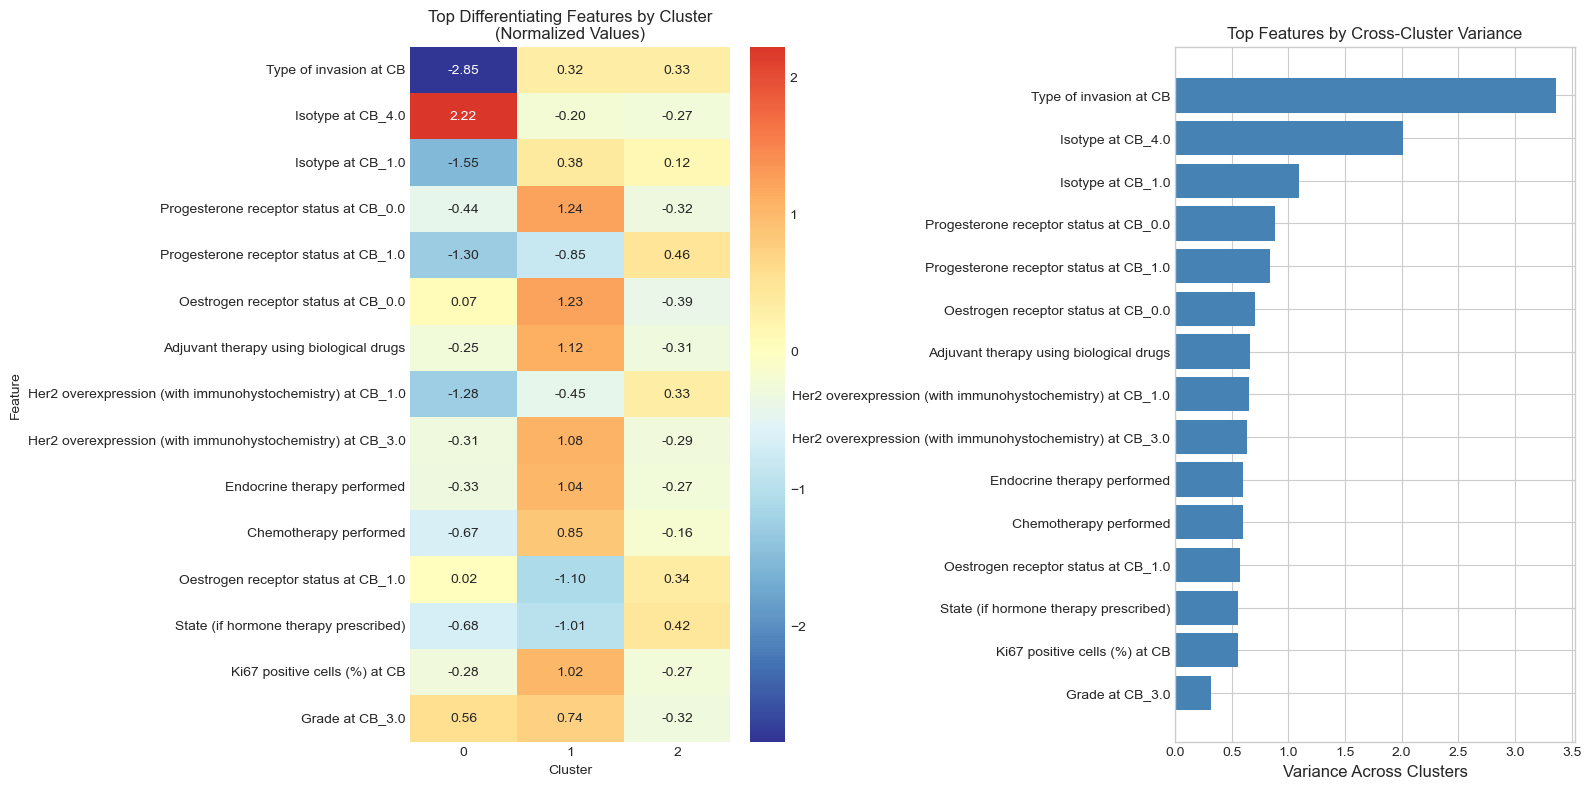


Top 15 features that differentiate clusters:
  1. Type of invasion at CB: variance = 3.3613
  2. Isotype at CB_4.0: variance = 2.0127
  3. Isotype at CB_1.0: variance = 1.0983
  4. Progesterone receptor status at CB_0.0: variance = 0.8806
  5. Progesterone receptor status at CB_1.0: variance = 0.8379
  6. Oestrogen receptor status at CB_0.0: variance = 0.7040
  7. Adjuvant therapy using biological drugs: variance = 0.6616
  8. Her2 overexpression (with immunohystochemistry) at CB_1.0: variance = 0.6496
  9. Her2 overexpression (with immunohystochemistry) at CB_3.0: variance = 0.6386
  10. Endocrine therapy performed: variance = 0.6001
  11. Chemotherapy performed: variance = 0.5986
  12. Oestrogen receptor status at CB_1.0: variance = 0.5700
  13. State (if hormone therapy prescribed): variance = 0.5575
  14. Ki67 positive cells (%) at CB: variance = 0.5570
  15. Grade at CB_3.0: variance = 0.3182


In [14]:
# Cell 14: Feature Analysis by Cluster - Which features differentiate clusters?
# Calculate mean feature values per cluster
cluster_means = pd.DataFrame(X_scaled, columns=feature_columns)
cluster_means['Cluster'] = cluster_labels_best
cluster_means = cluster_means.groupby('Cluster').mean()

# Find top differentiating features (by variance across clusters)
feature_variance = cluster_means.var(axis=0).sort_values(ascending=False)
top_features = feature_variance.head(15).index.tolist()

# Heatmap of top features by cluster
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# Heatmap
ax1 = axes[0]
sns.heatmap(cluster_means[top_features].T, annot=True, fmt='.2f', 
            cmap='RdYlBu_r', center=0, ax=ax1)
ax1.set_title('Top Differentiating Features by Cluster\n(Normalized Values)', fontsize=12)
ax1.set_xlabel('Cluster')
ax1.set_ylabel('Feature')

# Bar chart of feature variance
ax2 = axes[1]
ax2.barh(range(len(top_features)), feature_variance[top_features].values, color='steelblue')
ax2.set_yticks(range(len(top_features)))
ax2.set_yticklabels(top_features)
ax2.set_xlabel('Variance Across Clusters', fontsize=12)
ax2.set_title('Top Features by Cross-Cluster Variance', fontsize=12)
ax2.invert_yaxis()

plt.tight_layout()
plt.show()

# Print top features
print("\nTop 15 features that differentiate clusters:")
for i, (feat, var) in enumerate(feature_variance.head(15).items(), 1):
    print(f"  {i}. {feat}: variance = {var:.4f}")

In [15]:
# Cell 15: Save clustering results
# Add cluster labels to original dataset
results_df = survival_dataset.copy()
results_df['Cluster_KMeans'] = cluster_labels_best

# Save to CSV
results_df.to_csv('data_with_clusters.csv', index=False)
print("Results saved to 'data_with_clusters.csv'")

# Save cluster summary
cluster_summary = []
for c in range(best_k):
    mask = cluster_labels_best == c
    cluster_summary.append({
        'Cluster': c,
        'N_Samples': mask.sum(),
        'N_Events': int(event_status[mask].sum()),
        'Event_Rate': event_status[mask].mean(),
        'Mean_Survival_Days': survival_time[mask].mean(),
        'Median_Survival_Days': np.median(survival_time[mask])
    })

cluster_summary_df = pd.DataFrame(cluster_summary)
cluster_summary_df.to_csv('cluster_summary.csv', index=False)
print("Cluster summary saved to 'cluster_summary.csv'")
print("\n", cluster_summary_df.to_string(index=False))

Results saved to 'data_with_clusters.csv'
Cluster summary saved to 'cluster_summary.csv'

  Cluster  N_Samples  N_Events  Event_Rate  Mean_Survival_Days  Median_Survival_Days
       0        335         5    0.014925         1277.970149                1234.0
       1        687        14    0.020378         1405.841339                1303.0
       2       2205        14    0.006349         1440.316553                1372.0
